# Q1B | Display the Statistical Values

> *Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?*

This notebook answers the question in five parts:

1. **Feature types:** confirms every attribute is continuous, which determines the statistics and charts used.
2. **Statistical values:** descriptive statistics, missing values, skew, kurtosis, IQR outliers, and correlation with the target for every attribute.
3. **Distributions:** a histogram and a QQ plot for every attribute.
4. **Key attributes and noticeable traits:** which attributes matter most and what stands out about each.
5. **Special treatment:** skew transforms, outliers, missing values, and scaling.

A **Summary** at the end lists every attribute with the evidence and the recommended treatment.

### Imports

In [1]:
import math
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt

from Q1_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.preprocessing.transform import compare_all_transforms_for_df

### Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

> **IMPORTANT**
>
> This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`). Every statistic below is computed on the training rows only.

---

# 1. Feature Types

In [3]:
print(train_df.dtypes.value_counts().to_string())
print(f"Distinct values per column: min {train_df.nunique().min()}, max {train_df.nunique().max()}")

float64    9
Distinct values per column: min 354, max 1302


All 9 columns are numeric (`float64`) with at least 354 distinct values, so all are continuous. Each attribute gets continuous statistics, a histogram, and a QQ plot. There are no categorical or identifier columns, so nothing needs to be encoded or excluded.

# 2. Statistical Values

The statistics are split into two tables:

- **Descriptive statistics:** non-null count, missing values, mean, standard deviation, min, quartiles, max, and range.
- **Shape and outliers:**
  - `skew` and `excess kurtosis` (pandas reports excess kurtosis, so a normal distribution scores 0), each with a rule of thumb label
  - `Q1` (25th percentile), `Q3` (75th percentile), and `IQR` (Q3 - Q1), shown to 3 decimals so the fences can be reproduced
  - the IQR fences (Q1 - 1.5 × IQR and Q3 + 1.5 × IQR) and the number of values outside each fence
  - the Pearson correlation with the target, `Life Ladder`

Both tables are sorted by |skew|, largest first.

In [22]:
stats_df = train_df.describe().T
stats_df.insert(1, 'missing', train_df.isna().sum())
stats_df.insert(2, '% missing', (train_df.isna().mean() * 100))
stats_df['range'] = stats_df['max'] - stats_df['min']
stats_df['skew'] = train_df.skew()
stats_df['skew RoT'] = stats_df['skew'].map(lambda s: rule_of_thumb__skewness(value=s))
stats_df['excess kurtosis'] = train_df.kurt()
stats_df['kurtosis RoT'] = stats_df['excess kurtosis'].map(lambda k: rule_of_thumb__kurtosis(value=k))

q1, q3 = train_df.quantile(0.25), train_df.quantile(0.75)
iqr = q3 - q1
stats_df['Q1'] = q1
stats_df['Q3'] = q3
stats_df['IQR'] = iqr
stats_df['IQR lower fence'] = q1 - 1.5 * iqr
stats_df['IQR upper fence'] = q3 + 1.5 * iqr
stats_df['outliers below'] = (train_df < stats_df['IQR lower fence']).sum()
stats_df['outliers above'] = (train_df > stats_df['IQR upper fence']).sum()
stats_df['corr with target'] = train_df.corr()[TARGET]

stats_df = stats_df.sort_values('skew', key=abs, ascending=False)

descriptive_cols = ['count', 'missing', '% missing', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'range']
shape_cols = ['skew', 'skew RoT', 'excess kurtosis', 'kurtosis RoT', 'Q1', 'Q3', 'IQR', 'IQR lower fence', 'IQR upper fence', 'outliers below', 'outliers above', 'corr with target']

stats_df[descriptive_cols].round(2)

,count,missing,% missing,mean,std,min,25%,50%,75%,max,range
Perceptions of corruption,1473.0,86,5.52,0.75,0.19,0.04,0.69,0.80,0.87,0.98,0.95
Social support,1549.0,10,0.64,0.81,0.12,0.29,0.75,0.84,0.90,0.99,0.70
Generosity,1488.0,71,4.55,0.00,0.16,-0.34,-0.11,-0.02,0.09,0.70,1.03
Healthy life expectancy at birth,1522.0,37,2.37,63.33,7.48,32.30,58.34,65.18,68.54,77.10,44.80
Negative affect,1545.0,14,0.90,0.27,0.08,0.08,0.21,0.26,0.32,0.70,0.62
Freedom to make life choices,1537.0,22,1.41,0.74,0.14,0.26,0.65,0.76,0.86,0.98,0.72
Positive affect,1542.0,17,1.09,0.71,0.11,0.32,0.62,0.72,0.80,0.94,0.62
Log GDP per capita,1533.0,26,1.67,9.36,1.16,6.64,8.46,9.46,10.33,11.65,5.01
Life Ladder,1559.0,0,0.00,5.47,1.11,2.38,4.65,5.37,6.27,8.02,5.64


In [5]:
stats_df[shape_cols].round({'skew': 2, 'excess kurtosis': 2, 'Q1': 3, 'Q3': 3, 'IQR': 3, 'IQR lower fence': 3, 'IQR upper fence': 3, 'corr with target': 3})

,skew,skew RoT,excess kurtosis,kurtosis RoT,Q1,Q3,IQR,IQR lower fence,IQR upper fence,outliers below,outliers above,corr with target
Perceptions of corruption,-1.54,Highly skewed,2.01,"Leptokurtic (heavy tails, more outliers)",0.691,0.873,0.182,0.418,1.146,130,0,-0.428
Social support,-1.14,Highly skewed,1.30,"Leptokurtic (heavy tails, more outliers)",0.753,0.905,0.152,0.525,1.133,42,0,0.704
Generosity,0.83,Moderately skewed,0.94,Mesokurtic (near-normal tails),-0.113,0.091,0.204,-0.419,0.397,0,31,0.195
Healthy life expectancy at birth,-0.72,Moderately skewed,-0.09,Mesokurtic (near-normal tails),58.340,68.535,10.195,43.048,83.827,7,0,0.751
Negative affect,0.70,Moderately skewed,0.80,Mesokurtic (near-normal tails),0.206,0.319,0.113,0.036,0.489,0,20,-0.302
Freedom to make life choices,-0.61,Moderately skewed,-0.16,Mesokurtic (near-normal tails),0.646,0.855,0.209,0.333,1.168,8,0,0.530
Positive affect,-0.35,Roughly symmetric,-0.61,Mesokurtic (near-normal tails),0.623,0.798,0.175,0.360,1.061,2,0,0.535
Log GDP per capita,-0.29,Roughly symmetric,-0.86,Mesokurtic (near-normal tails),8.460,10.332,1.872,5.652,13.140,0,0,0.787
Life Ladder,0.07,Roughly symmetric,-0.67,Mesokurtic (near-normal tails),4.650,6.272,1.623,2.215,8.707,0,0,1.000


- **Missing values:** Perceptions of corruption (86) and Generosity (71) have the most. Life Ladder has none.
- **Skew:** 6 of the 8 features have |skew| ≥ 0.5. Perceptions of corruption (-1.54) and Social support (-1.14) are highly skewed to the left. Generosity (0.83) and Negative affect (0.70) are skewed to the right.
	- TODO: add explanation for Skew Range & Skew Rule of Thumb (RoT)
- **Tails:** Perceptions of corruption (2.01) and Social support (1.30) are the only leptokurtic features. Every other attribute is mesokurtic.
	- - TODO: add explanation for Excess Kurtosis Range (vs Kurtosis Range) & Kurtosis Rule of Thumb (RoT)
- **Outliers:** Perceptions of corruption has 130 IQR outliers, all below the 0.418 lower fence. Log GDP per capita and Life Ladder have none.
- **Scale:** ranges run from 0.62 (Positive affect and Negative affect) to 44.80 (Healthy life expectancy at birth).

# 3. Distributions

## Histograms with Normal Distribution Overlay

Each histogram is drawn as a density, so the bar area adds up to 1 and the bars are on the same scale as a normal curve fitted with the attribute's mean and standard deviation. The vertical lines mark the mean and ±1, 2, and 3 standard deviations.

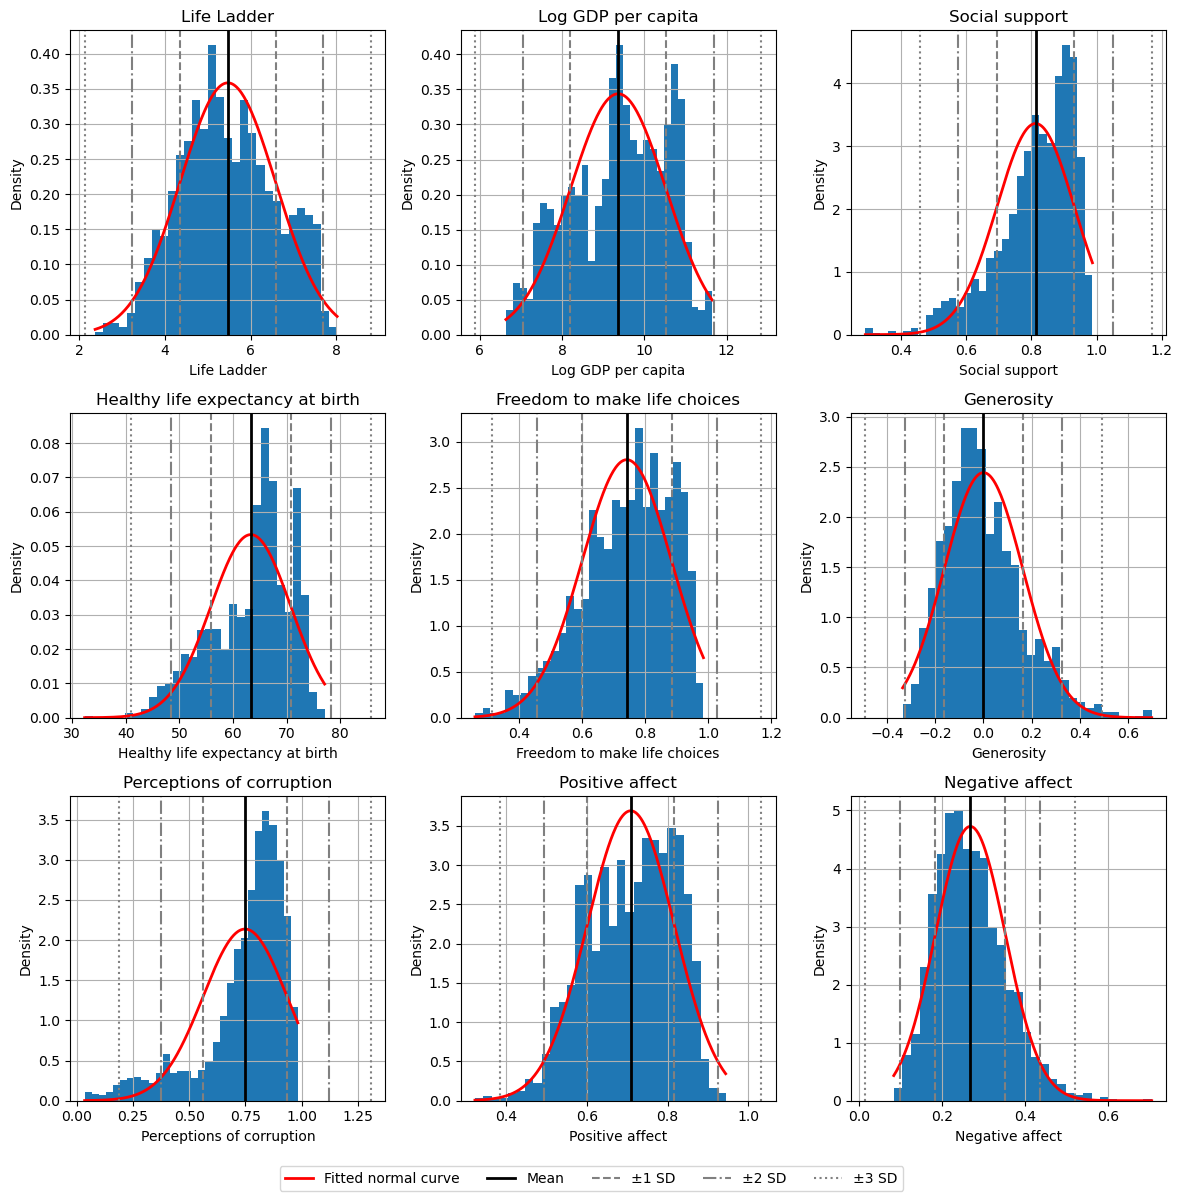

In [6]:
columns = train_df.columns
ncols = 3
nrows = math.ceil(len(columns) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, columns):
	plot_hist_with_normal_dist_overlay(series=train_df[col], bins=HIST_BINS, ax=ax)
	ax.set_xlabel(col)
	ax.set_ylabel('Density')
	ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
labels[0] = 'Fitted normal curve'
fig.legend(handles, labels, loc='lower center', ncol=5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

- Life Ladder (skew 0.07) and Log GDP per capita (skew -0.29) closely follow the fitted normal curve.
- Perceptions of corruption and Social support pile up near their maximum with a long tail to the left, matching their negative skew.
- Generosity and Negative affect have tails to the right, with a few values well past +2 SD.

## QQ Plots

A QQ plot compares each attribute's sorted values with the values a normal distribution would produce. Points on the red line match a normal distribution.

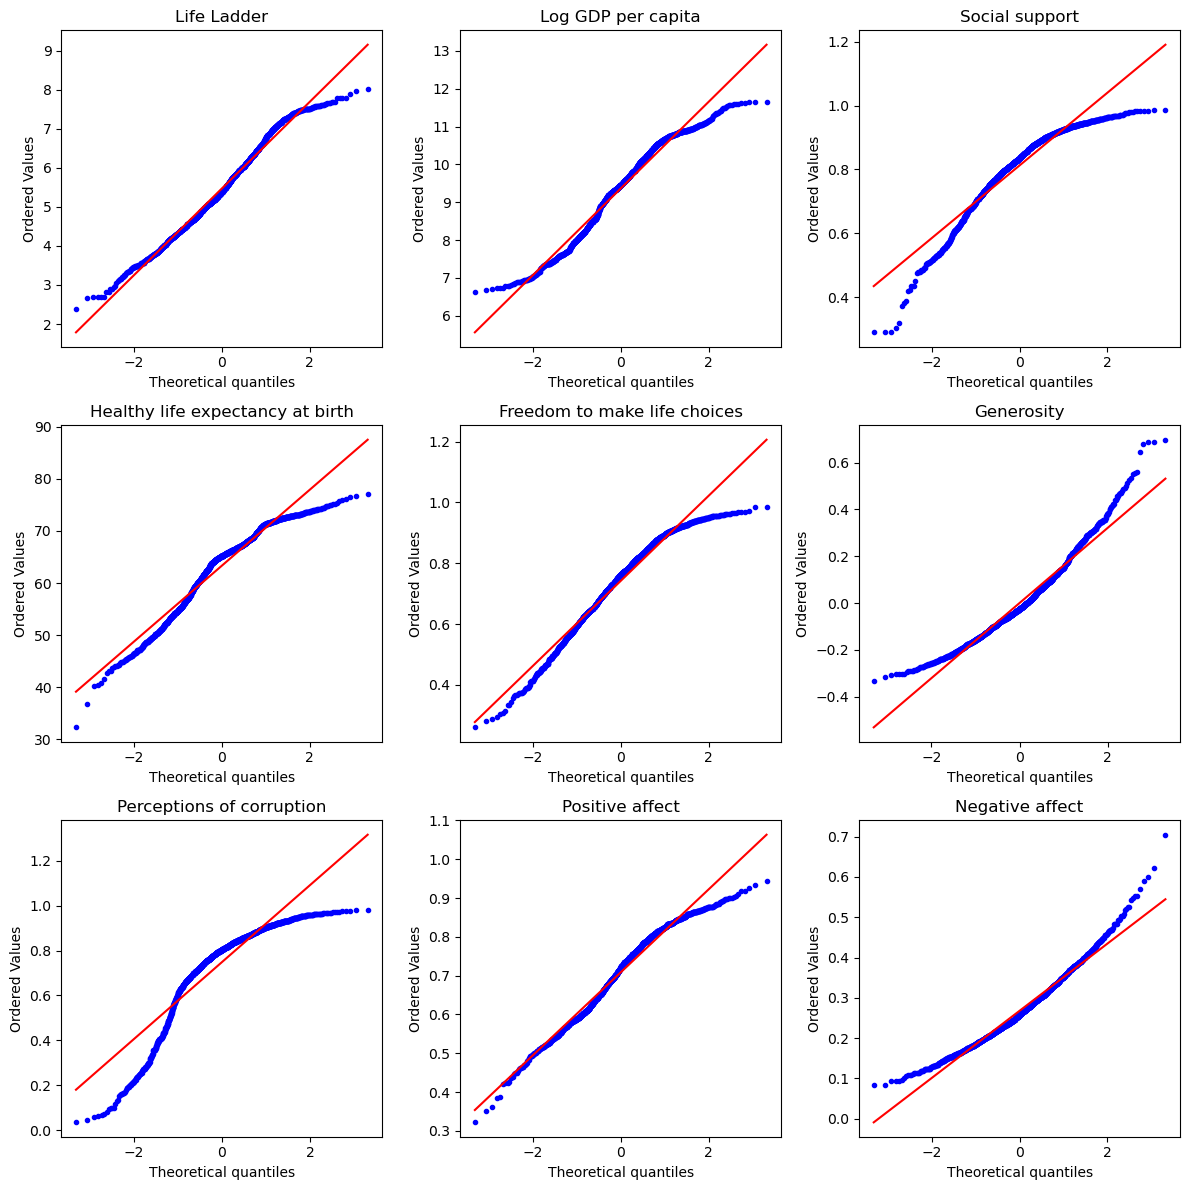

In [7]:
columns = train_df.columns
ncols = 3
nrows = math.ceil(len(columns) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, columns):
	stats.probplot(
		train_df[col].dropna(),
		dist="norm",
		plot=ax)
	ax.set_title(col)  # probplot titles every plot "Probability Plot" by default
	ax.get_lines()[0].set_markersize(3)  # data points; get_lines()[1] is the red reference line

plt.tight_layout()
plt.show()

- Life Ladder stays close to the line through most of its range.
- Perceptions of corruption and Social support drop well below the line at the low end, which is the long left tail.
- Generosity and Negative affect rise above the line at the high end, which is the long right tail.

---

# 4. Key Attributes and Noticeable Traits

**Key attributes**

- **Life Ladder** is the target.
- **Log GDP per capita** (r = 0.787) and **Healthy life expectancy at birth** (r = 0.751) have the strongest correlation with the target.
- **Perceptions of corruption** has the largest |skew| (1.54), the most IQR outliers (130), and the most missing values (86).

**Noticeable traits**

- **Life Ladder:** no missing values, skew 0.07, no IQR outliers, and it stays close to the QQ line through most of its range. It needs no special treatment.
- **Log GDP per capita:** skew -0.29 and no IQR outliers. Its only issue is 26 missing values.
- **Healthy life expectancy at birth:** moderately skewed to the left (-0.72) with 7 outliers below the 43.048 fence, and 37 missing values.
- **Perceptions of corruption:** highly skewed to the left (-1.54) and leptokurtic (2.01), with all 130 outliers at the low end. Section 5 shows these low values have a higher Life Ladder than the rest of the data.

# 5. Special Treatment

## Skewed Features

Reducing skew is not a goal in itself. A transform is only worth it when it makes the feature's relationship to the target easier for the model to learn. "Correlation with the target" is a decent proxy, but validated model performance is the real test.

With that said, below are the results of each skewed column after every numeric transform (log, sqrt, powers, Yeo-Johnson), ranked by `fixes_skew` and then `corr_gain`.

- `none`: the untransformed column, the baseline every other row is compared against
- `skew` / `skew_rule` / `fixes_skew`: the skew after the transform, and whether it is now under 0.5
- `kurt`: kurtosis after the transform, for reference
- `corr_with_target`: Pearson correlation with `Life Ladder` after the transform
- `corr_gain`: change in |correlation| compared to `none`. Positive means the relationship got stronger and more linear

Rank and bucket transforms are left out on purpose. Both replace each value with its position or its group, so the actual distances between values are lost, and those distances are what a linear model's slope relies on. Buckets are only useful one-hot encoded, which is a separate decision.

In [8]:
skewed_columns = stats_df.index[(stats_df['skew'].abs() >= 0.5) & (stats_df.index != TARGET)].tolist()
transformed_df = compare_all_transforms_for_df(df=train_df[skewed_columns + [TARGET]], target=TARGET)
transformed_df

skew          skew_rule  \
feature                          transform                                  
Perceptions of corruption        yeo_johnson -0.294346  Roughly symmetric   
                                 none        -1.536457      Highly skewed   
                                 power_0.75  -1.784183      Highly skewed   
                                 sqrt        -2.095595      Highly skewed   
                                 power_0.25  -2.510537      Highly skewed   
                                 log         -3.097482      Highly skewed   
Social support                   yeo_johnson -0.174370  Roughly symmetric   
                                 none        -1.137804      Highly skewed   
                                 power_0.75  -1.278152      Highly skewed   
                                 sqrt        -1.438064      Highly skewed   
                                 power_0.25  -1.622454      Highly skewed   
                                 log         -1.837504      Highly skewed   
Generosity                       log          0.465337  Roughly symmetric   
                                 power_0.75   0.457872  Roughly symmetric   
                                 yeo_johnson  0.025929  Roughly symmetric   
                                 sqrt         0.049354  Roughly symmetric   
                                 none         0.828245  Moderately skewed   
                                 power_0.25  -0.596841  Moderately skewed   
Healthy life expectancy at birth yeo_johnson -0.141241  Roughly symmetric   
                                 none        -0.722594  Moderately skewed   
                                 power_0.75  -0.790452  Moderately skewed   
                                 sqrt        -0.861621  Moderately skewed   
                                 power_0.25  -0.936667  Moderately skewed   
                                 log         -1.016284      Highly skewed   
Negative affect                  power_0.75   0.459423  Roughly symmetric   
                                 sqrt         0.228431  Roughly symmetric   
                                 yeo_johnson  0.014468  Roughly symmetric   
                                 power_0.25  -0.001524  Roughly symmetric   
                                 log         -0.235408  Roughly symmetric   
                                 none         0.696474  Moderately skewed   
Freedom to make life choices     yeo_johnson -0.100027  Roughly symmetric   
                                 none        -0.606357  Moderately skewed   
                                 power_0.75  -0.733569  Moderately skewed   
                                 sqrt        -0.873144  Moderately skewed   
                                 power_0.25  -1.027181      Highly skewed   
                                 log         -1.198154      Highly skewed   

                                              fixes_skew       kurt  \
feature                          transform                            
Perceptions of corruption        yeo_johnson        True  -0.698718   
                                 none              False   2.005973   
                                 power_0.75        False   3.084768   
                                 sqrt              False   4.750336   
                                 power_0.25        False   7.524766   
                                 log               False  12.497849   
Social support                   yeo_johnson        True  -0.871743   
                                 none              False   1.297841   
                                 power_0.75        False   1.903981   
                                 sqrt              False   2.692411   
                                 power_0.25        False   3.730253   
                                 log               False   5.110435   
Generosity                       log                True   0.148579   
                                 power_0.75         True  

The table above, reduced to one decision per feature. A transform is kept only if it:

1. Fixes the skew (`fixes_skew` is True)
2. Raises |correlation| with the target by at least `MIN_CORR_GAIN` (0.02), the minimum gain treated as meaningful in this analysis

When more than one transform passes, the largest `corr_gain` wins. Features where nothing passes keep their raw column (`none`), since no transform made the relationship with the target better. `Perceptions of corruption` is the clearest case: Yeo-Johnson fixes its skew but lowers |correlation| with the target from 0.428 to 0.381 (`corr_gain` = -0.046).

The gains for `Healthy life expectancy at birth` and `Freedom to make life choices` are borderline, so they should be confirmed by comparing cross-validated model performance with and without the transform.

In [9]:
MIN_CORR_GAIN = 0.02

filtered_transformed_df = transformed_df.copy()
filtered_transformed_df = filtered_transformed_df[
	filtered_transformed_df['fixes_skew']
	& (filtered_transformed_df['corr_gain'] >= MIN_CORR_GAIN)
]

# Best remaining transform per feature, and the raw column for features where nothing passed
best = filtered_transformed_df.sort_values('corr_gain', ascending=False).groupby(level='feature').head(1)
keep_raw = [f for f in skewed_columns if f not in best.index.get_level_values('feature')]
decisions = pd.concat([best, transformed_df.loc[[(f, 'none') for f in keep_raw]]])
decisions

,,skew,skew_rule,fixes_skew,kurt,corr_with_target,corr_gain
feature,transform,,,,,,
Social support,yeo_johnson,-0.174370,Roughly symmetric,True,-0.871743,0.746457,0.042579
Healthy life expectancy at birth,yeo_johnson,-0.141241,Roughly symmetric,True,-0.826676,0.777385,0.026612
Freedom to make life choices,yeo_johnson,-0.100027,Roughly symmetric,True,-0.847414,0.551407,0.021588
Perceptions of corruption,none,-1.536457,Highly skewed,False,2.005973,-0.427562,0.000000
Generosity,none,0.828245,Moderately skewed,False,0.944684,0.194970,0.000000
Negative affect,none,0.696474,Moderately skewed,False,0.801214,-0.301821,0.000000


**Special treatment:** apply Yeo-Johnson to Social support (+0.043), Healthy life expectancy at birth (+0.027), and Freedom to make life choices (+0.022). Keep Perceptions of corruption, Generosity, and Negative affect raw, since no transform passed both criteria.

## Perceptions of Corruption: Low-Value Outliers Have a Higher Life Ladder

The IQR rule flags 130 low Corruption values as outliers. Before clipping or dropping them, check whether they behave differently on the target. The scatter plot shows the relationship, and the rows are then split at Corruption = 0.5, the split point used for the comparison below.

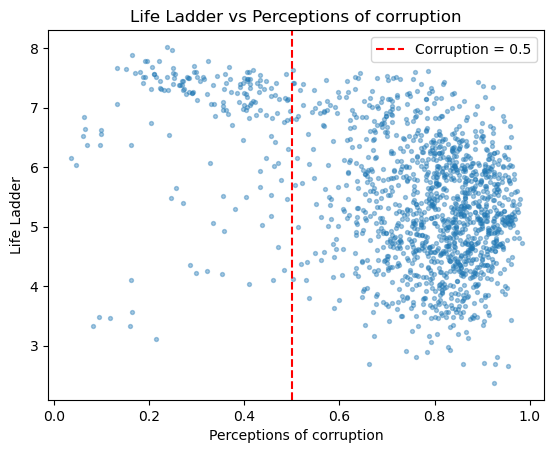

In [10]:
fig, ax = plt.subplots()
ax.scatter(train_df['Perceptions of corruption'], train_df[TARGET], s=8, alpha=0.4)
ax.axvline(0.5, color='red', ls='--', label='Corruption = 0.5')
ax.set_xlabel('Perceptions of corruption')
ax.set_ylabel(TARGET)
ax.set_title(f'{TARGET} vs Perceptions of corruption')
ax.legend()
plt.show()

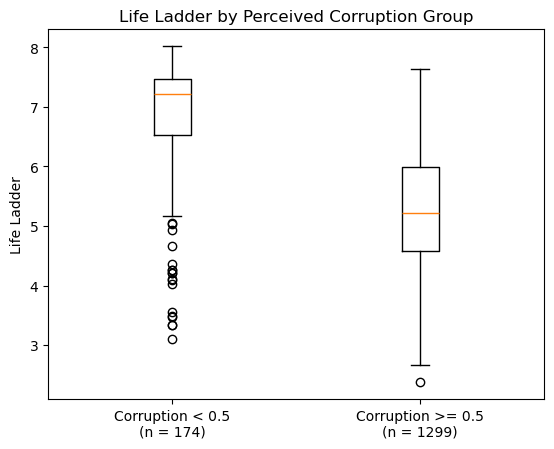

Mean Life Ladder: low corruption = 6.76, high corruption = 5.28
       Corruption < 0.5  Corruption >= 0.5
count           174.000           1299.000
mean              6.765              5.285
std               1.095              1.007
min               3.108              2.375
25%               6.531              4.574
50%               7.219              5.220
75%               7.472              5.998
max               8.019              7.632
Correlation within Corruption >= 0.5: -0.183


In [11]:
corruption = train_df['Perceptions of corruption']
low_group = train_df.loc[corruption < 0.5, TARGET]
high_group = train_df.loc[corruption >= 0.5, TARGET]

fig, ax = plt.subplots()
ax.boxplot([low_group, high_group])
ax.set_xticks([1, 2], labels=[
	f'Corruption < 0.5\n(n = {len(low_group)})',
	f'Corruption >= 0.5\n(n = {len(high_group)})',
])
ax.set_ylabel(TARGET)
ax.set_title(f'{TARGET} by Perceived Corruption Group')
plt.show()

print(f'Mean {TARGET}: low corruption = {low_group.mean():.2f}, high corruption = {high_group.mean():.2f}')

print(pd.DataFrame({
	'Corruption < 0.5': low_group.describe(),
	'Corruption >= 0.5': high_group.describe(),
}).round(3))

high = train_df.loc[corruption >= 0.5]
print(f"Correlation within Corruption >= 0.5: {high['Perceptions of corruption'].corr(high[TARGET]):.3f}")

### Notes / Observations
- The IQR lower fence for Corruption is 0.418, below the 0.5 split, so all 130 outliers are in the low group. That is 130 of the 174 rows in the low group.
- These rows have a higher Life Ladder: mean 6.76 vs 5.28 for the rest. The low group's middle half (6.531 to 7.472) sits entirely above the high group's 75th percentile (5.998).
- At 0.5 and above, Corruption has a correlation of only -0.183 with Life Ladder, and Life Ladder spans 2.375 to 7.632. This is the L shape in the scatter plot above.

### Special treatment:
Do **not** clip or remove these outliers, since they carry most of this feature's signal. For a linear model, add a binary "low corruption" flag (Corruption < 0.5) or a spline / polynomial term so the model can capture the bend. Tree based models capture it on their own.

## Missing Values Occur Together

This chart shows which features go missing **together**. Each cell counts training rows missing both the row feature and the column feature. The diagonal is each feature's total.

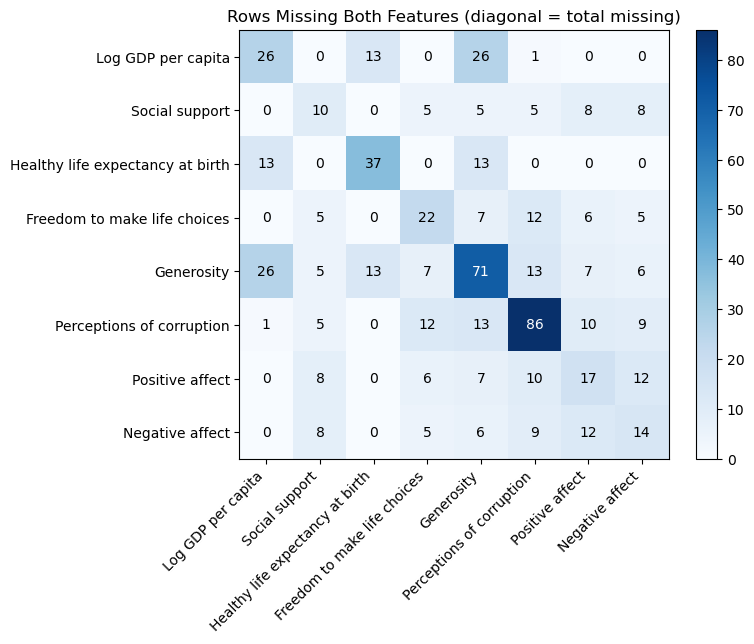

missing values in row
0    1374
1     130
2      27
3      23
6       5
Complete rows: 1374 (88.13%)
Rows with any missing value: 185 (11.87%)
Columns present in the 5 rows missing 6 values: ['Life Ladder', 'Log GDP per capita', 'Healthy life expectancy at birth']


In [12]:
features = train_df.columns.drop(TARGET)
is_missing = train_df[features].isna().astype(int)
co_missing = is_missing.T @ is_missing

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(co_missing, cmap='Blues')
ax.set_xticks(range(len(features)), labels=features, rotation=45, ha='right')
ax.set_yticks(range(len(features)), labels=features)

# white text on dark cells, black on light cells
for i in range(len(features)):
	for j in range(len(features)):
		value = co_missing.iloc[i, j]
		ax.text(j, i, value, ha='center', va='center', color='white' if value > co_missing.values.max() / 2 else 'black')

ax.set_title('Rows Missing Both Features (diagonal = total missing)')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

print(train_df.isna().sum(axis=1).value_counts().sort_index().rename_axis('missing values in row').rename('rows').to_string())

missing_per_row = train_df.isna().sum(axis=1)
print(f"Complete rows: {(missing_per_row == 0).sum()} ({(missing_per_row == 0).mean() * 100:.2f}%)")
print(f"Rows with any missing value: {(missing_per_row > 0).sum()} ({(missing_per_row > 0).mean() * 100:.2f}%)")
sparse = train_df[missing_per_row == missing_per_row.max()]
print(f"Columns present in the {len(sparse)} rows missing {missing_per_row.max()} values: {sparse.columns[sparse.notna().all()].tolist()}")

### Notes / Observations
- **Every row missing Log GDP (26) is also missing Generosity.**
- Half of those rows (13) are also missing Healthy life expectancy, so the two features with the strongest correlation to the target (Log GDP 0.787, Healthy life expectancy 0.751) tend to be missing together.
- Social support, Freedom, Corruption, Positive affect, and Negative affect are never missing in the same row as Healthy life expectancy (0 in every cell), and only 1 row is missing both Log GDP and Perceptions of corruption. Within these five, missing values overlap often: Positive and Negative affect are both missing in 12 rows, and Freedom and Corruption are both missing in 12 rows.
- 1,374 rows (88.13%) are complete and 130 are missing just one value, but **5 rows are missing 6 of the 8 features**, keeping only Life Ladder, Log GDP per capita, and Healthy life expectancy at birth.

### Special treatment:
  - Impute rather than drop, since dropping every incomplete row loses 185 rows (11.87%) of the training data. Use the median, since 6 of the 8 features have |skew| ≥ 0.5 (skew table), and fit the imputer on the training set only.
  - A multivariate imputer (KNN or iterative) could fill one strong predictor from another, but Log GDP and Healthy life expectancy are missing in the same 13 rows, so it has less to work with exactly where it would help most.
  - Consider dropping the 5 rows missing 6 of 8 features, since imputing them would mostly be made up data.

## Feature Scales

In [13]:
stats_df[['min', 'max', 'range']].sort_values('range').round(2)

,min,max,range
Positive affect,0.32,0.94,0.62
Negative affect,0.08,0.70,0.62
Social support,0.29,0.99,0.70
Freedom to make life choices,0.26,0.98,0.72
Perceptions of corruption,0.04,0.98,0.95
Generosity,-0.34,0.70,1.03
Log GDP per capita,6.64,11.65,5.01
Life Ladder,2.38,8.02,5.64
Healthy life expectancy at birth,32.30,77.10,44.80


The ranges run from 0.62 (Positive affect and Negative affect) to 44.80 (Healthy life expectancy at birth).

### Special treatment:
Standardize the features for any model that is sensitive to feature scale,.

---

# Summary

- **Statistical values:** Section 2 shows the descriptive statistics, missing values, skew, kurtosis, IQR outliers, and target correlation for all 9 attributes.
- **Visualizations:** Section 3 shows a histogram with a fitted normal curve and a QQ plot for all 9 attributes.
- **Noticeable traits for key attributes:** Life Ladder is close to normal with no missing values or outliers. Log GDP per capita and Healthy life expectancy at birth have the strongest correlation with the target and are often missing together. Perceptions of corruption is the most skewed attribute, and its 130 low-value outliers have a higher Life Ladder than the rest of the data.
- **Special treatment:**

| Attribute | Evidence | Treatment |
|---|---|---|
| Perceptions of corruption | 86 missing (5.52%), skew -1.54, kurtosis 2.01, 130 outliers below 0.418, mean Life Ladder 6.76 (< 0.5) vs 5.28 | Keep outliers. Median impute. Add a Corruption < 0.5 flag or spline term for linear models. No transform. |
| Social support | 10 missing, skew -1.14, kurtosis 1.30, 42 outliers below | Yeo-Johnson. Median impute. |
| Healthy life expectancy at birth | 37 missing (13 with Log GDP), skew -0.72, 7 outliers below | Yeo-Johnson (borderline). Median impute. |
| Freedom to make life choices | 22 missing, skew -0.61, 8 outliers below | Yeo-Johnson (borderline). Median impute. |
| Generosity | 71 missing (all 26 Log GDP rows), skew 0.83, 31 outliers above | Keep raw. Median impute. |
| Negative affect | 14 missing, skew 0.70, 20 outliers above | Keep raw. Median impute. |
| Log GDP per capita | 26 missing, skew -0.29, 0 outliers | Median impute only. |
| Positive affect | 17 missing, skew -0.35, 2 outliers below | Median impute only. |
| Life Ladder (target) | 0 missing, skew 0.07, 0 outliers | None. |
| All features | Ranges 0.62 to 44.80 | Standardize (fit on train) for scale-sensitive models. |
| 5 sparse rows | Missing 6 of 8 features | Consider dropping. |